# Cenário 3 - Estratégia Mista 

In [43]:
%pip install pandas matplotlib openpyxl holidays -q
%matplotlib inline

Note: you may need to restart the kernel to use updated packages.


In [44]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import holidays
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, FixedLocator

df_consumo = pd.read_excel('medicao_5_minutos_2025_PRDOCMENTR101.xlsx')

print(df_consumo.info())
print(df_consumo["coleta_tipo"].unique())

<class 'pandas.DataFrame'>
RangeIndex: 113922 entries, 0 to 113921
Data columns (total 11 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Unnamed: 0          113922 non-null  int64  
 1   coleta_tipo         113922 non-null  str    
 2   data                113922 non-null  str    
 3   medidor             113922 non-null  str    
 4   tipo_energia        113922 non-null  str    
 5   ea_consumo_valor    113922 non-null  float64
 6   ea_consumo_unidade  113922 non-null  str    
 7   ea_geracao_valor    113922 non-null  int64  
 8   er_consumo_valor    113922 non-null  float64
 9   er_consumo_unidade  113922 non-null  str    
 10  er_geracao_valor    113922 non-null  float64
dtypes: float64(3), int64(2), str(6)
memory usage: 15.7 MB
None
<ArrowStringArray>
['Coleta Diária', 'Inspeção Lógica']
Length: 2, dtype: str


In [45]:
# ============================================================
# PADRÃO DE FIGURAS PARA O TCC
# Execute esta célula antes de qualquer gráfico.
# Todas as figuras são salvas somente em PDF (vetorial).
# ============================================================

NOME_SISTEMA = "SAEB"            # nome usado nas legendas ("Sem SAEB", "Com SAEB")
LARGURA_CM, ALTURA_CM = 16, 7.5
DPI = 300
PASTA_SAIDA = "figuras cenário 3"   # pasta das figuras do TCC
os.makedirs(PASTA_SAIDA, exist_ok=True)

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.titlesize": 10,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "savefig.dpi": DPI,
    "pdf.fonttype": 42,          # fontes incorporadas como texto no PDF
})

COR_DESCARGA = "tab:red"
COR_CARGA = "tab:green"
HORA_FIM_CARGA = 6               # carga das 23h às 06h (solução 3)

MESES = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
         "Jul", "Ago", "Set", "Out", "Nov", "Dez"]

cm = 1 / 2.54

def tam(largura_cm=LARGURA_CM, altura_cm=ALTURA_CM):
    return (largura_cm * cm, altura_cm * cm)

TAMANHO = tam()

# ------------------------------------------------------------------
# Formatação de números e rótulos
# ------------------------------------------------------------------
def fmt_br(x, _=None):
    """Número no padrão brasileiro: 1.234,5."""
    s = f"{x:,.2f}"
    if s.endswith(".00"):
        s = s[:-3]
    elif s.endswith("0"):
        s = s[:-1]
    return s.replace(",", "X").replace(".", ",").replace("X", ".")

def eixo_y_br(eixo):
    eixo.yaxis.set_major_formatter(FuncFormatter(fmt_br))

def rotulos_meses(indice):
    """Converte '2025-01' / Period em 'Jan', 'Fev', ..."""
    return [MESES[int(str(p)[-2:]) - 1] for p in indice]

# ------------------------------------------------------------------
# Eixo x
# ------------------------------------------------------------------
def formatar_eixo_x(eixo, inicio, fim, rotulo_h=12, menor_h=6,
                    fmt="%d/%m\n%H:%M", xlabel="Data e hora"):
    """Eixo de tempo: rótulos a cada `rotulo_h` horas, marcas menores a cada `menor_h`."""
    eixo.set_xlim(inicio, fim)
    eixo.xaxis.set_major_locator(
        mdates.HourLocator(byhour=range(0, 24, rotulo_h)))
    eixo.xaxis.set_major_formatter(mdates.DateFormatter(fmt))
    eixo.xaxis.set_minor_locator(
        mdates.HourLocator(byhour=[h for h in range(0, 24, menor_h)
                                   if h % rotulo_h != 0]))
    eixo.tick_params(axis="x", which="minor", length=3)
    eixo.set_xlabel(xlabel)

def eixo_x_meses(eixo, ano):
    """Eixo de um ano inteiro, com rótulos Jan ... Dez no início de cada mês."""
    eixo.set_xlim(pd.Timestamp(ano, 1, 1), pd.Timestamp(ano + 1, 1, 1))
    posicoes = [mdates.date2num(pd.Timestamp(ano, m, 1)) for m in range(1, 13)]
    eixo.xaxis.set_major_locator(FixedLocator(posicoes))
    eixo.xaxis.set_major_formatter(
        FuncFormatter(lambda x, _: MESES[mdates.num2date(x).month - 1]))
    eixo.set_xlabel("Mês")

# ------------------------------------------------------------------
# Faixas de carga/descarga, legenda e barras
# ------------------------------------------------------------------
def dia_tem_ponta(dia):
    """Ponta só existe em dia útil que não seja feriado."""
    return dia.weekday() < 5 and dia.date() not in feriados

def marcar_periodos(eixo, inicio, fim):
    """Sombreia descarga (18h-21h) e carga (23h até HORA_FIM_CARGA do dia seguinte)."""
    inicio, fim = pd.Timestamp(inicio), pd.Timestamp(fim)
    for dia in pd.date_range(inicio.normalize() - pd.Timedelta(days=1),
                             fim.normalize(), freq="D"):
        if dia_tem_ponta(dia):
            eixo.axvspan(dia + pd.Timedelta(hours=18), dia + pd.Timedelta(hours=21),
                         color=COR_DESCARGA, alpha=0.12, linewidth=0)
        # recarga de madrugada todos os dias
        eixo.axvspan(dia + pd.Timedelta(hours=23),
                     dia + pd.Timedelta(days=1, hours=HORA_FIM_CARGA),
                     color=COR_CARGA, alpha=0.12, linewidth=0)

def legenda_abaixo(eixo, ncol, y=-0.27, periodos=False):
    """Legenda abaixo do gráfico. y=-0.27 para rótulos de 2 linhas, ~-0.19 para 1 linha."""
    handles, _ = eixo.get_legend_handles_labels()
    if periodos:
        handles += [
            Patch(facecolor=COR_DESCARGA, alpha=0.25, label="Período de descarga"),
            Patch(facecolor=COR_CARGA, alpha=0.25, label="Período de carga"),
        ]
    eixo.legend(handles=handles, loc="upper center",
                bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)

def estilo_barras(eixo):
    eixo.set_axisbelow(True)
    eixo.xaxis.grid(False)
    eixo.yaxis.grid(True, alpha=0.3)

def barras_agrupadas(eixo, rotulos, series, cores=None):
    """Barras lado a lado. `series` = {nome: valores}."""
    n = len(series)
    larg = 0.8 / n
    x = np.arange(len(rotulos))
    for i, (nome, valores) in enumerate(series.items()):
        eixo.bar(x + (i - (n - 1) / 2) * larg, valores, larg, label=nome,
                 color=None if cores is None else cores[i], zorder=2)
    eixo.set_xticks(x)
    eixo.set_xticklabels(rotulos)
    eixo.set_xlabel("Mês")
    estilo_barras(eixo)

def salvar(fig, nome):
    """Salva SOMENTE em PDF e exibe a figura."""
    fig.savefig(f"{PASTA_SAIDA}/{nome}.pdf", bbox_inches="tight")
    plt.show()

In [46]:
df_consumo = df_consumo[df_consumo["coleta_tipo"] == "Coleta Diária"]
print(df_consumo.info())
df_analise = df_consumo[["data", "ea_consumo_valor"]].copy()

# print(df_analise.head(10))
print(df_analise.info())

<class 'pandas.DataFrame'>
Index: 103780 entries, 0 to 113921
Data columns (total 11 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Unnamed: 0          103780 non-null  int64  
 1   coleta_tipo         103780 non-null  str    
 2   data                103780 non-null  str    
 3   medidor             103780 non-null  str    
 4   tipo_energia        103780 non-null  str    
 5   ea_consumo_valor    103780 non-null  float64
 6   ea_consumo_unidade  103780 non-null  str    
 7   ea_geracao_valor    103780 non-null  int64  
 8   er_consumo_valor    103780 non-null  float64
 9   er_consumo_unidade  103780 non-null  str    
 10  er_geracao_valor    103780 non-null  float64
dtypes: float64(3), int64(2), str(6)
memory usage: 15.1 MB
None
<class 'pandas.DataFrame'>
Index: 103780 entries, 0 to 113921
Data columns (total 2 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 

In [47]:
df_analise['data'] = pd.to_datetime(df_analise['data'])

df_analise = df_analise[
    df_analise['data'] < '2026-01-01'
]

print(df_analise.info())
print(df_analise['data'].iloc[:5])
print(df_analise['ea_consumo_valor'].iloc[:5])

<class 'pandas.DataFrame'>
Index: 103779 entries, 0 to 113920
Data columns (total 2 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   data              103779 non-null  datetime64[us]
 1   ea_consumo_valor  103779 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 2.4 MB
None
0   2025-01-01 00:05:00
1   2025-01-01 00:10:00
2   2025-01-01 00:15:00
3   2025-01-01 00:20:00
4   2025-01-01 00:25:00
Name: data, dtype: datetime64[us]
0    10.458
1    10.458
2    10.584
3    10.584
4    10.458
Name: ea_consumo_valor, dtype: float64


In [48]:
df_original = df_analise.copy()

Quantidade de zeros restantes: 0
Todos os valores iguais a zero foram corrigidos!

Quantidade de valores substituídos: 257


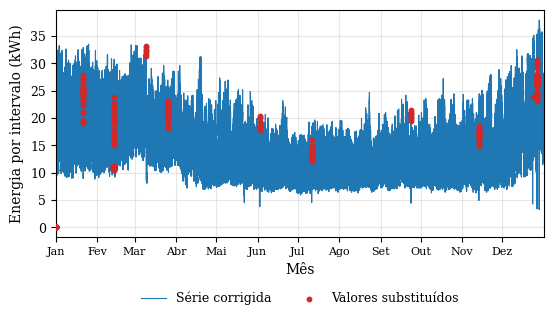

In [49]:
# ============================================================
# 1. PREPARAÇÃO DOS DADOS
# ============================================================

# Guarda os valores originais antes da correção
df_analise['ea_consumo_original'] = df_analise['ea_consumo_valor'].copy()

# ============================================================
# 2. IDENTIFICA OS VALORES QUE FORAM CORTADOS
# ============================================================

# Somente valores originalmente iguais a zero serão corrigidos
mask_zero = df_analise['ea_consumo_valor'] < 3

# ============================================================
# 3. CRIA UMA SÉRIE PARA CONSULTAR OS VALORES ORIGINAIS
# ============================================================

serie_original = (
    df_analise
    .set_index('data')['ea_consumo_valor']
    .copy()
)

# ============================================================
# 4. CORREÇÃO PRINCIPAL
#
# Procura o mesmo horário:
# 1 semana antes
# 2 semanas antes
# 3 semanas antes
# 4 semanas antes
# ============================================================

for semanas in [1, 2, 3, 4]:

    # Datas correspondentes às semanas anteriores
    datas_busca = (
        df_analise.loc[mask_zero, 'data']
        - pd.Timedelta(weeks=semanas)
    )

    # Procura exatamente o mesmo horário
    valores = serie_original.reindex(datas_busca).values

    # Só aceita valores existentes e maiores que zero
    valores_validos = (
        pd.notna(valores) &
        (valores > 0)
    )

    # Índices dos zeros que ainda precisam ser corrigidos
    indices_zero = df_analise.index[mask_zero]

    # Substitui somente os zeros que encontraram referência válida
    df_analise.loc[
        indices_zero[valores_validos],
        'ea_consumo_valor'
    ] = valores[valores_validos]

    # Atualiza a máscara
    mask_zero = df_analise['ea_consumo_valor'] == 0

    # Se não existem mais zeros, encerra
    if not mask_zero.any():
        break

# ============================================================
# 5. SEGUNDA TENTATIVA
#
# Para os zeros restantes:
# procura o mesmo DIA DA SEMANA + mesmo HORÁRIO
# nas semanas anteriores.
# ============================================================

mask_zero = df_analise['ea_consumo_valor'] == 0

# Cria informações auxiliares
df_analise['dia_semana'] = df_analise['data'].dt.dayofweek
df_analise['horario'] = df_analise['data'].dt.strftime('%H:%M')

# Percorre somente os zeros restantes
for indice in df_analise.index[mask_zero]:

    data_zero = df_analise.loc[indice, 'data']
    dia_semana = df_analise.loc[indice, 'dia_semana']
    horario = df_analise.loc[indice, 'horario']

    # Procura valores positivos:
    # mesmo dia da semana
    # mesmo horário
    # anteriores à data do zero
    candidatos = df_analise[
        (df_analise['dia_semana'] == dia_semana) &
        (df_analise['horario'] == horario) &
        (df_analise['data'] < data_zero) &
        (df_analise['ea_consumo_original'] > 0)
    ]

    # Mantém somente candidatos das últimas 8 semanas
    candidatos = candidatos[
        candidatos['data'] >= data_zero - pd.Timedelta(weeks=8)
    ]

    if not candidatos.empty:

        # Pega o valor mais recente
        candidato = candidatos.sort_values(
            'data',
            ascending=False
        ).iloc[0]

        df_analise.loc[
            indice,
            'ea_consumo_valor'
        ] = candidato['ea_consumo_original']

# ============================================================
# 6. TERCEIRA TENTATIVA
#
# Se ainda houver zeros:
# procura no mesmo dia da semana e mesma hora,
# mas permite uma diferença de até 5 minutos.
# ============================================================

mask_zero = df_analise['ea_consumo_valor'] == 0

for indice in df_analise.index[mask_zero]:

    data_zero = df_analise.loc[indice, 'data']
    dia_semana = df_analise.loc[indice, 'dia_semana']

    hora_zero = data_zero.hour
    minuto_zero = data_zero.minute

    # Seleciona mesmo dia da semana
    candidatos = df_analise[
        (df_analise['dia_semana'] == dia_semana) &
        (df_analise['ea_consumo_original'] > 0) &
        (df_analise['data'] < data_zero)
    ].copy()

    # Últimas 8 semanas
    candidatos = candidatos[
        candidatos['data'] >= data_zero - pd.Timedelta(weeks=8)
    ]

    if not candidatos.empty:

        # Diferença em minutos entre os horários
        candidatos['dif_minutos'] = (
            abs(
                candidatos['data'].dt.hour * 60 +
                candidatos['data'].dt.minute -
                (hora_zero * 60 + minuto_zero)
            )
        )

        # Aceita somente diferenças de até 5 minutos
        candidatos = candidatos[
            candidatos['dif_minutos'] <= 5
        ]

        if not candidatos.empty:

            # Primeiro escolhe o horário mais próximo
            # e, em caso de empate, o mais recente
            candidato = (
                candidatos
                .sort_values(
                    ['dif_minutos', 'data'],
                    ascending=[True, False]
                )
                .iloc[0]
            )

            df_analise.loc[
                indice,
                'ea_consumo_valor'
            ] = candidato['ea_consumo_original']

# ============================================================
# 6.5. QUARTA TENTATIVA
#
# Para os zeros que sobraram mesmo após buscar em semanas
# anteriores (provável falha sistemática do medidor, que se
# repete no mesmo horário todas as semanas): interpola usando
# os pontos vizinhos no tempo, dentro do próprio dia.
# ============================================================

mask_zero = df_analise['ea_consumo_valor'] == 0

if mask_zero.any():

    serie_tempo = (
        df_analise
        .set_index('data')['ea_consumo_valor']
        .replace(0, np.nan)
    )

    # Interpolação por tempo (respeita o espaçamento real entre
    # os registros, mesmo em dias com granularidade diferente)
    # limitada a lacunas curtas (até 30 min) para não "inventar"
    # valores em buracos grandes
    serie_interpolada = serie_tempo.interpolate(
        method='time',
        limit=6,          # até 6 registros consecutivos (~30 min em dados de 5 min)
        limit_direction='both'
    )

    df_analise.loc[mask_zero, 'ea_consumo_valor'] = (
        serie_interpolada
        .reindex(df_analise.loc[mask_zero, 'data'])
        .values
    )

# ============================================================
# 7. VERIFICA QUANTOS ZEROS AINDA EXISTEM
# ============================================================

zeros_restantes = (
    df_analise['ea_consumo_valor'] == 0
).sum()

print(
    f'Quantidade de zeros restantes: {zeros_restantes}'
)

# ============================================================
# 8. MOSTRA OS ZEROS QUE EVENTUALMENTE RESTARAM
# ============================================================

if zeros_restantes > 0:

    print('\nValores que ainda não foram corrigidos:')

    display(
        df_analise.loc[
            df_analise['ea_consumo_valor'] == 0,
            [
                'data',
                'ea_consumo_original',
                'ea_consumo_valor'
            ]
        ]
    )

else:

    print('Todos os valores iguais a zero foram corrigidos!')

# ============================================================
# 9. IDENTIFICA OS VALORES QUE FORAM SUBSTITUÍDOS
# ============================================================

mask_corrigidos = (
    (df_analise['ea_consumo_original'] == 0) &
    (df_analise['ea_consumo_valor'] > 0)
)

print(
    f'\nQuantidade de valores substituídos: '
    f'{mask_corrigidos.sum()}'
)

# ============================================================
# 10. GRÁFICO PARA CONFERIR A CORREÇÃO
# ============================================================

fig, ax = plt.subplots(figsize=TAMANHO)

ax.plot(df_analise['data'], df_analise['ea_consumo_valor'],
        label='Série corrigida', linewidth=0.8, rasterized=True)

ax.scatter(df_analise.loc[mask_corrigidos, 'data'],
           df_analise.loc[mask_corrigidos, 'ea_consumo_valor'],
           label='Valores substituídos', s=10, color='tab:red', zorder=3)

eixo_x_meses(ax, df_analise['data'].dt.year.min())
ax.set_ylabel('Energia por intervalo (kWh)')
legenda_abaixo(ax, ncol=2, y=-0.19)
salvar(fig, 'fig_correcao_consumo')

# ============================================================
# 11. REMOVE COLUNAS AUXILIARES
# ============================================================

df_analise.drop(
    columns=['dia_semana', 'horario'],
    inplace=True
)

In [50]:
# ============================================================
# REAMOSTRAGEM PARA 15 MINUTOS
# ============================================================
# Guarda a série de 5 min (usada só para comparar original x corrigido)
df_analise_5min = df_analise.copy()

# Os timestamps do medidor marcam o FIM do intervalo
# (o primeiro registro é 00:05 e existe um 2026-01-01 00:00).
# Por isso: closed='right' e label='left'.
# O registro das 00:15 pertence ao intervalo 00:00-00:15, e o rótulo
# do bloco passa a ser o INÍCIO do intervalo (00:00).
g = (
    df_analise
    .set_index('data')
    .sort_index()['ea_consumo_valor']
    .resample('15min', closed='right', label='left')
)

soma = g.sum()
n = g.count()   # quantos registros de 5 min existem em cada bloco

# Se faltar leitura no bloco (n < 3), escala a soma para 3 leituras.
# Blocos sem nenhuma leitura (n = 0) são descartados.
df_15 = pd.DataFrame({
    'ea_consumo_valor': soma * 3 / n.replace(0, np.nan)
}).dropna().reset_index()

df_analise = df_15
print('Registros em 15 min:', len(df_analise))   # esperado: ~35.040
print(df_analise.head())

Registros em 15 min: 34618
                 data  ea_consumo_valor
0 2025-01-01 00:00:00            31.500
1 2025-01-01 00:15:00            31.752
2 2025-01-01 00:30:00            32.130
3 2025-01-01 00:45:00            32.382
4 2025-01-01 01:00:00            32.886


In [51]:
# Para uma análise tarifária mais realista, o ideal é excluir também os feriados nacionais (e eventualmente estaduais/municipais).

feriados = holidays.Brazil(years=[2025])
# Adicionar manualmente Carnaval e Corpus Christi
feriados[pd.Timestamp('2025-03-04').date()] = "Carnaval"
feriados[pd.Timestamp('2025-06-19').date()] = "Corpus Christi"
# Criamos uma coluna de feriados:

df_analise['feriado'] = (
    df_analise['data'].dt.date
    .isin(feriados)
)

# mostra os feriados encontrados no período do dataset
for data, nome in feriados.items():
    print(data, "-", nome)

# 2. Classificar os períodos

df_analise['periodo'] = np.where(
    (
        (df_analise['data'].dt.weekday < 5) &
        (~df_analise['feriado']) &
        (df_analise['data'].dt.hour >= 18) &
        (df_analise['data'].dt.hour < 21)
    ),
    'Ponta',
    'Fora de Ponta'
)

# 3. Somar o consumo por período

consumo_periodo = (
    df_analise
    .groupby('periodo')['ea_consumo_valor']
    .sum()
)
print('==============================')
print(consumo_periodo)

2025-01-01 - Confraternização Universal
2025-04-18 - Sexta-feira Santa
2025-04-21 - Tiradentes
2025-05-01 - Dia do Trabalhador
2025-09-07 - Independência do Brasil
2025-10-12 - Nossa Senhora Aparecida
2025-11-02 - Finados
2025-11-15 - Proclamação da República
2025-11-20 - Dia Nacional de Zumbi e da Consciência Negra
2025-12-25 - Natal
2025-03-04 - Carnaval
2025-06-19 - Corpus Christi
periodo
Fora de Ponta    1418228.595
Ponta             177417.324
Name: ea_consumo_valor, dtype: float64


In [52]:
# 4. Consumo mensal por período

df_analise['mes'] = df_analise['data'].dt.to_period('M')

consumo_mensal = (
    df_analise
    .groupby(['mes', 'periodo'])['ea_consumo_valor']
    .sum()
    .unstack()
)

print(consumo_mensal.head(12))

periodo  Fora de Ponta      Ponta
mes                              
2025-01     158695.740  21807.702
2025-02     138117.420  18381.384
2025-03     154705.446  17093.412
2025-04     116490.402  13875.876
2025-05     113321.376  14236.488
2025-06      91374.318  10732.428
2025-07      90016.290  12037.788
2025-08      89681.382  10769.724
2025-09      93563.694  12481.560
2025-10     103230.666  13912.290
2025-11     113615.838  12769.596
2025-12     155416.023  19319.076


         Fora de Ponta      Ponta  Fora de Ponta Fatura  Ponta Fatura  \
mes                                                                     
2025-01     158695.740  21807.702                158471         21806   
2025-02     138117.420  18381.384                137226         18381   
2025-03     154705.446  17093.412                154166         17030   
2025-04     116490.402  13875.876                119288         13879   
2025-05     113321.376  14236.488                113321         14236   
2025-06      91374.318  10732.428                 92474         10730   
2025-07      90016.290  12037.788                 90136         12036   
2025-08      89681.382  10769.724                 92830         10766   
2025-09      93563.694  12481.560                 96066         12475   
2025-10     103230.666  13912.290                103662         13912   
2025-11     113615.838  12769.596                113539         12769   
2025-12     155416.023  19319.076                15

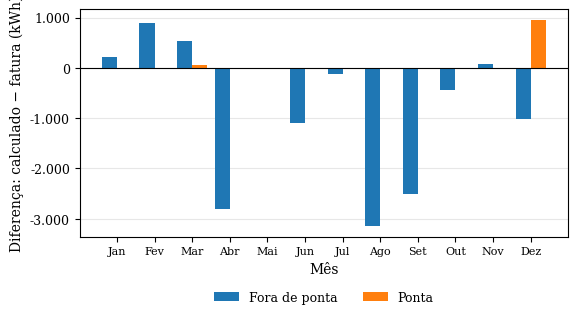

         Erro_%_Fora_Ponta  Erro_%_Ponta
mes                                     
2025-01               0.14          0.01
2025-02               0.65          0.00
2025-03               0.35          0.37
2025-04              -2.35         -0.02
2025-05               0.00          0.00
2025-06              -1.19          0.02
2025-07              -0.13          0.01
2025-08              -3.39          0.03
2025-09              -2.60          0.05
2025-10              -0.42          0.00
2025-11               0.07          0.00
2025-12              -0.64          5.25
MAPE Fora de Ponta: 0.99%
MAPE Ponta: 0.48%


In [53]:
fatura = pd.DataFrame({
    'Fora de Ponta Fatura': [158471,137226,154166,119288,
                             113321,92474,90136,92830,96066,103662,113539,156422],
    'Ponta Fatura': [21806,18381,17030,13879,
                     14236,10730,12036,10766,12475,13912,12769,18356]
},
index=['2025-01','2025-02','2025-03','2025-04','2025-05','2025-06',
       '2025-07','2025-08','2025-09','2025-10','2025-11','2025-12'])

consumo_mensal.index = consumo_mensal.index.astype(str)

comparacao = consumo_mensal.join(fatura)

comparacao['Dif_Fora_Ponta'] = (
    comparacao['Fora de Ponta'] -
    comparacao['Fora de Ponta Fatura']
)

comparacao['Dif_Ponta'] = (
    comparacao['Ponta'] -
    comparacao['Ponta Fatura']
)

print(comparacao.head(12))

fig, ax = plt.subplots(figsize=TAMANHO)

barras_agrupadas(
    ax,
    rotulos_meses(comparacao.index),
    {'Fora de ponta': comparacao['Dif_Fora_Ponta'].values,
     'Ponta': comparacao['Dif_Ponta'].values}
)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('Diferença: calculado − fatura (kWh)')
eixo_y_br(ax)
legenda_abaixo(ax, ncol=2, y=-0.19)
salvar(fig, 'fig_diferenca_energia_fatura')

comparacao['Erro_%_Fora_Ponta'] = (
    (comparacao['Fora de Ponta'] - comparacao['Fora de Ponta Fatura']) /
    comparacao['Fora de Ponta Fatura']
) * 100

comparacao['Erro_%_Ponta'] = (
    (comparacao['Ponta'] - comparacao['Ponta Fatura']) /
    comparacao['Ponta Fatura']
) * 100

print(comparacao[['Erro_%_Fora_Ponta', 'Erro_%_Ponta']].round(2))

mape_fora = comparacao['Erro_%_Fora_Ponta'].abs().mean()
mape_ponta = comparacao['Erro_%_Ponta'].abs().mean()

print(f"MAPE Fora de Ponta: {mape_fora:.2f}%")
print(f"MAPE Ponta: {mape_ponta:.2f}%")

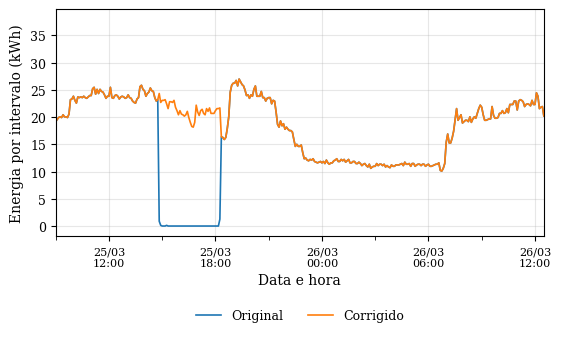

In [54]:
fig, ax = plt.subplots(figsize=TAMANHO)

ax.plot(df_original['data'], df_original['ea_consumo_valor'],
        label='Original', linewidth=1.2)
ax.plot(df_analise_5min['data'], df_analise_5min['ea_consumo_valor'],
        label='Corrigido', linewidth=1.2)

formatar_eixo_x(ax,
                pd.Timestamp('2025-03-25 09:00'),
                pd.Timestamp('2025-03-26 12:30'),
                rotulo_h=6, menor_h=3)
ax.set_ylabel('Energia por intervalo (kWh)')
legenda_abaixo(ax, ncol=2)
salvar(fig, 'fig_correcao_zoom')

In [55]:
# Garante que fica só o ano de 2025
df_analise = df_analise[df_analise['data'].dt.year == 2025].copy()

# 2. Extrair dia e hora de cada registro
df_analise['dia'] = df_analise['data'].dt.date
df_analise['hora'] = df_analise['data'].dt.hour

# 3. Somar os intervalos de 15 min dentro de cada hora, para cada dia
# Cada leitura de ea_consumo_valor é o consumo do intervalo, em kWh.
# Somando os 4 intervalos de uma hora obtemos o kWh consumido naquela hora.
consumo_por_dia_hora = (
    df_analise.groupby(['dia', 'hora'])['ea_consumo_valor']
    .sum()
    .reset_index(name='kwh_hora')
)

# 4. Tirar a média entre todos os dias do ano,
# para cada hora do dia (0h a 23h)
perfil_medio_diario = (
    consumo_por_dia_hora.groupby('hora')['kwh_hora']
    .mean()
    .reset_index(name='kwh_medio')
)

print(perfil_medio_diario)

    hora   kwh_medio
0      0  115.529227
1      1  113.384811
2      2  111.663616
3      3  111.065030
4      4  110.090515
5      5  109.155008
6      6  121.400827
7      7  184.852701
8      8  194.763896
9      9  207.249633
10    10  222.034784
11    11  230.047003
12    12  225.896942
13    13  231.798921
14    14  230.781945
15    15  230.200619
16    16  235.879940
17    17  244.860805
18    18  247.850285
19    19  238.102718
20    20  224.842340
21    21  195.288000
22    22  155.421000
23    23  122.661771


Consumo médio diário em ponta:      710.8 kWh
Consumo médio diário fora de ponta: 3704.0 kWh


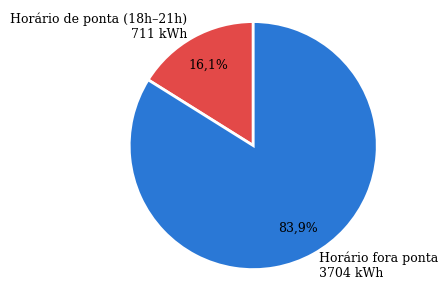

In [56]:
# Horário de ponta: 18h às 21h (intervalo de 3 horas: 18h-19h, 19h-20h, 20h-21h)
ponta_inicio = 18
ponta_fim = 21

mask_ponta = (perfil_medio_diario['hora'] >= ponta_inicio) & (perfil_medio_diario['hora'] < ponta_fim)

consumo_ponta = perfil_medio_diario.loc[mask_ponta, 'kwh_medio'].sum()
consumo_fora_ponta = perfil_medio_diario.loc[~mask_ponta, 'kwh_medio'].sum()

print(f'Consumo médio diário em ponta:      {consumo_ponta:.1f} kWh')
print(f'Consumo médio diário fora de ponta: {consumo_fora_ponta:.1f} kWh')

# Gráfico de pizza
valores = [consumo_ponta, consumo_fora_ponta]
labels = [f'Horário de ponta (18h–21h)\n{consumo_ponta:.0f} kWh',
          f'Horário fora ponta\n{consumo_fora_ponta:.0f} kWh']
cores = ['#e34948', '#2a78d6']

fig, ax = plt.subplots(figsize=tam(12, 9))
ax.pie(valores, labels=labels, colors=cores,
       autopct=lambda p: f'{p:.1f}%'.replace('.', ','),
       startangle=90, pctdistance=0.75,
       textprops={'fontsize': 9},
       wedgeprops={'edgecolor': 'white', 'linewidth': 2})
ax.axis('equal')
salvar(fig, 'fig_pizza_consumo_ponta')

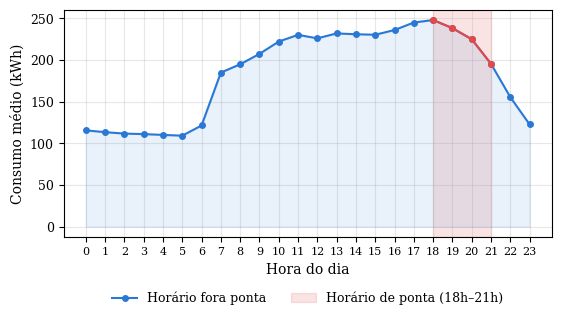

In [57]:
fig, ax = plt.subplots(figsize=TAMANHO)

# Curva principal (fora de ponta)
ax.plot(perfil_medio_diario['hora'], perfil_medio_diario['kwh_medio'],
        marker='o', markersize=4, linewidth=1.5, color='#2a78d6', zorder=3,
        label='Horário fora ponta')
ax.fill_between(perfil_medio_diario['hora'], perfil_medio_diario['kwh_medio'],
                alpha=0.1, color='#2a78d6', zorder=2)

# Destaque da faixa de ponta (18h-21h)
ax.axvspan(ponta_inicio, ponta_fim, color='#e34948', alpha=0.15, zorder=1,
           label='Horário de ponta (18h–21h)')

# Reforça os pontos dentro da ponta em vermelho, por cima da curva azul
mask_ponta = ((perfil_medio_diario['hora'] >= ponta_inicio) &
              (perfil_medio_diario['hora'] <= ponta_fim))
ax.plot(perfil_medio_diario.loc[mask_ponta, 'hora'],
        perfil_medio_diario.loc[mask_ponta, 'kwh_medio'],
        marker='o', markersize=4, linewidth=1.5, color='#e34948', zorder=4)

ax.set_xlabel('Hora do dia')
ax.set_ylabel('Consumo médio (kWh)')
ax.set_xticks(range(0, 24))
legenda_abaixo(ax, ncol=2, y=-0.19)
salvar(fig, 'fig_perfil_medio_diario')

In [58]:
media_geral = perfil_medio_diario['kwh_medio'].mean()
print(f'Média do perfil médio diário: {media_geral:.1f} kWh')

Média do perfil médio diário: 184.0 kWh


mes
2025-01     62082.885326
2025-02     59401.545344
2025-03    103639.151573
2025-04     63442.339299
2025-05     65865.501877
2025-06     52665.211838
2025-07     50549.787677
2025-08     57395.016266
2025-09     58340.432876
2025-10     63262.361770
2025-11     70228.458840
2025-12     95743.383455
Freq: M, dtype: float64


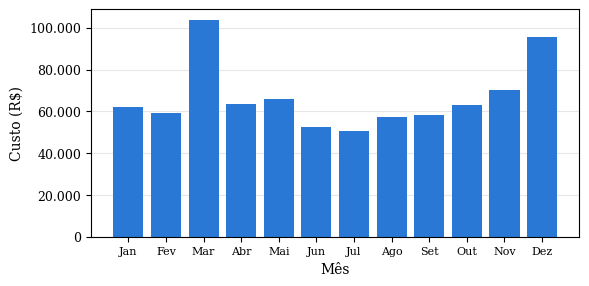

In [59]:
# nao consegui acesso a uma fatura da comercializadora real entao pedi para ia gerar uma media de valores de cada mes utilizando
# dados da internet
# cenario para tarifa verde que é a usada atualmente pelo consumidor

#-----------------------------------------------------------------
# ============================================================
# CUSTO EM R$ USANDO PLD MÉDIO MENSAL (SUBMERCADO SUL) COMO PROXY
# DO PREÇO DA ENERGIA — fonte: CCEE, Dados Abertos, PLD_MEDIA_MENSAL
# ============================================================

# PLD médio mensal 2025 - Submercado Sul (R$/MWh)
pld_sul_2025 = {
    1: 59.21,  2: 93.83,  3: 332.56, 4: 202.98,
    5: 233.39, 6: 236.10, 7: 211.67, 8: 287.17,
    9: 260.34, 10: 250.18, 11: 278.02, 12: 265.89
}
pld_sul_2025_kwh = {mes: v / 1000 for mes, v in pld_sul_2025.items()}  # R$/kWh

# Tarifas TUSD extraídas da fatura real (já "com tributos")
TUSD_ENERGIA_PONTA = 0.907026       # R$/kWh
TUSD_ENERGIA_FORA_PONTA = 0.164487  # R$/kWh
TUSD_DEMANDA = 14.147461            # R$/kW

df_analise['mes_num'] = df_analise['data'].dt.month
df_analise['mes'] = df_analise['data'].dt.to_period('M')
df_analise['pld_kwh'] = df_analise['mes_num'].map(pld_sul_2025_kwh)

# Custo de energia (commodity via PLD + TUSD energia) por intervalo de 15 min
df_analise['custo_energia_reais'] = np.where(
    df_analise['periodo'] == 'Ponta',
    df_analise['ea_consumo_valor'] * (df_analise['pld_kwh'] + TUSD_ENERGIA_PONTA),
    df_analise['ea_consumo_valor'] * (df_analise['pld_kwh'] + TUSD_ENERGIA_FORA_PONTA)
)

# Soma por mês
custo_energia_mensal = df_analise.groupby('mes')['custo_energia_reais'].sum()

# Custo de demanda: TUSD demanda x pico de potência medido no mês
# kWh em 15 min -> kW médio: x 4
df_analise['potencia_kw'] = df_analise['ea_consumo_valor'] * 4
demanda_medida_mensal = df_analise.groupby('mes')['potencia_kw'].max()
custo_demanda_mensal = demanda_medida_mensal * TUSD_DEMANDA

# Custo total mensal
custo_total_mensal = custo_energia_mensal + custo_demanda_mensal

print(custo_total_mensal)

# Gráfico de barras
fig, ax = plt.subplots(figsize=TAMANHO)
ax.bar(rotulos_meses(custo_total_mensal.index), custo_total_mensal.values,
       color='#2a78d6', zorder=2)
estilo_barras(ax)
eixo_y_br(ax)
ax.set_xlabel('Mês')
ax.set_ylabel('Custo (R$)')
salvar(fig, 'fig_custo_total_mensal_pld_tusd')

mes
2025-01     87508.232598
2025-02     85007.420785
2025-03    131190.654865
2025-04     89787.154274
2025-05     88626.739995
2025-06     70610.145348
2025-07     65045.290346
2025-08     75734.685573
2025-09     78118.849369
2025-10     84346.993103
2025-11     95008.765047
2025-12    125264.017842
Freq: M, dtype: float64
            Verde (R$)      Azul (R$)  Diferença (R$)
mes                                                  
2025-01   62082.885326   87508.232598    25425.347271
2025-02   59401.545344   85007.420785    25605.875441
2025-03  103639.151573  131190.654865    27551.503291
2025-04   63442.339299   89787.154274    26344.814974
2025-05   65865.501877   88626.739995    22761.238118
2025-06   52665.211838   70610.145348    17944.933510
2025-07   50549.787677   65045.290346    14495.502668
2025-08   57395.016266   75734.685573    18339.669307
2025-09   58340.432876   78118.849369    19778.416493
2025-10   63262.361770   84346.993103    21084.631333
2025-11   70228.458840  

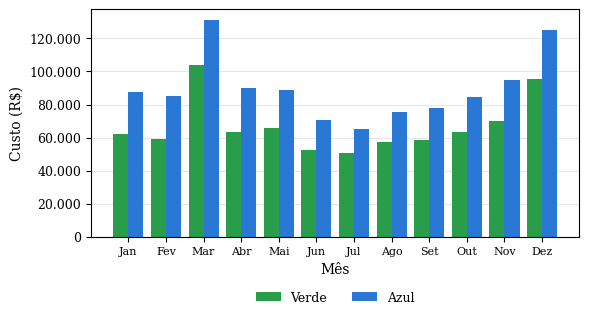

In [60]:
# nao consegui acesso a uma fatura da comercializadora real entao pedi para ia gerar uma media de valores de cada mes do mercado livre de energia
# utilizadno dados da internet

# Tarifas TUSD Azul (com tributos) - subgrupo A4, fonte: site da Copel
TUSD_DEMANDA_PONTA_AZUL = 72.50       # R$/kW
TUSD_DEMANDA_FORA_PONTA_AZUL = 33.93  # R$/kW
TUSD_ENERGIA_AZUL = 0.19635           # R$/kWh (tarifa única - mesma na ponta e fora ponta)

# Custo de energia (PLD + TUSD-Azul) por intervalo de 15 min
# Como a TUSD-energia é única na Azul, não precisa diferenciar por período aqui
df_analise['custo_energia_reais_azul'] = (
    df_analise['ea_consumo_valor'] * (df_analise['pld_kwh'] + TUSD_ENERGIA_AZUL)
)
custo_energia_mensal_azul = df_analise.groupby('mes')['custo_energia_reais_azul'].sum()

# Demanda ponta e fora ponta medidas por mês (picos separados)
demanda_ponta_mensal = df_analise[df_analise['periodo'] == 'Ponta'].groupby('mes')['potencia_kw'].max()
demanda_fp_mensal = df_analise[df_analise['periodo'] != 'Ponta'].groupby('mes')['potencia_kw'].max()

custo_demanda_mensal_azul = (
    demanda_ponta_mensal * TUSD_DEMANDA_PONTA_AZUL +
    demanda_fp_mensal * TUSD_DEMANDA_FORA_PONTA_AZUL
)

custo_total_mensal_azul = custo_energia_mensal_azul + custo_demanda_mensal_azul
print(custo_total_mensal_azul)

# Comparação Verde x Azul
comparacao_modalidades = pd.DataFrame({
    'Verde (R$)': custo_total_mensal,
    'Azul (R$)': custo_total_mensal_azul
})
comparacao_modalidades['Diferença (R$)'] = comparacao_modalidades['Azul (R$)'] - comparacao_modalidades['Verde (R$)']
print(comparacao_modalidades)

fig, ax = plt.subplots(figsize=TAMANHO)
barras_agrupadas(
    ax,
    rotulos_meses(comparacao_modalidades.index),
    {'Verde': comparacao_modalidades['Verde (R$)'].values,
     'Azul': comparacao_modalidades['Azul (R$)'].values},
    cores=['#2a9d4a', '#2a78d6']
)
ax.set_ylabel('Custo (R$)')
eixo_y_br(ax)
legenda_abaixo(ax, ncol=2, y=-0.19)
salvar(fig, 'fig_custo_verde_azul')

mes
2025-01    991.259182
2025-02    919.069200
2025-03    854.670600
2025-04    693.793800
2025-05    677.928000
2025-06    536.621400
2025-07    523.382087
2025-08    512.844000
2025-09    567.343636
2025-10    604.882174
2025-11    672.084000
2025-12    878.139818
Freq: M, Name: ea_consumo_valor, dtype: float64


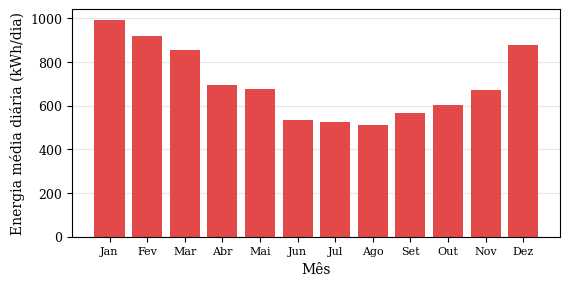

In [61]:
# 1) soma a energia em ponta por dia
consumo_ponta_diario = (
    df_analise[df_analise['periodo'] == 'Ponta']
    .groupby(['mes', 'dia'])['ea_consumo_valor']
    .sum()
    .reset_index()
)

# 2) tira a média diária dentro de cada mês
consumo_ponta_media_diaria_mensal = (
    consumo_ponta_diario
    .groupby('mes')['ea_consumo_valor']
    .mean()
)

print(consumo_ponta_media_diaria_mensal)

# Gráfico de barras
fig, ax = plt.subplots(figsize=TAMANHO)
ax.bar(rotulos_meses(consumo_ponta_media_diaria_mensal.index),
       consumo_ponta_media_diaria_mensal.values,
       color='#e34948', zorder=2)
estilo_barras(ax)
ax.set_xlabel('Mês')
ax.set_ylabel('Energia média diária (kWh/dia)')
salvar(fig, 'fig_consumo_medio_diario_ponta')

In [62]:
# ==================================================
# Parâmetros do BESS
# ==================================================

capacidade = 723.0        # kWh (3 módulos)
pot_carga = 375.0         # kW
pot_descarga = 375.0      # kW

soc_min = 0.20
soc_max = 0.95

soc = 0.50 * capacidade

eta_carga = 0.95
eta_descarga = 0.95

dt = 15 / 60              # horas

rampa_carga = 60.0        # kW por intervalo (equivale a 20 kW por 5 min)
rampa_descarga = 300.0    # kW por intervalo (equivale a 100 kW por 5 min)

pot_bat_anterior = 0.0

# ==================================================
# Parâmetro do Peak Shaving
# ==================================================

limite_demanda_kw = 370

# ==================================================
# Vetores de resultados
# ==================================================

soc_hist = []
pot_rede_hist = []
pot_bat_hist = []
estrategia_hist = []

# ==================================================
# Simulação
# PRIORIDADE: Load Shifting (ponta) > Peak Shaving > Carregamento
# ==================================================

# Dias em que a bateria opera: dias úteis, sem feriados
df_analise["dia_util"] = (
    (df_analise["data"].dt.weekday < 5) &
    (~df_analise["feriado"])
)

for row in df_analise.itertuples(index=False):

    data_hora = row.data
    hora_decimal = (
        data_hora.hour
        + data_hora.minute / 60
        + data_hora.second / 3600
    )

    carga = row.potencia_kw
    pot_bat_desejada = 0.0
    estrategia = "Ocioso"

    energia_disponivel = soc - capacidade * soc_min
    pot_maxima_por_energia = energia_disponivel * eta_descarga / dt

    # ==================================================
    # 1) Load Shifting - prioridade máxima na ponta (18h-21h)
    # Descarrega para atender toda a carga enquanto houver energia
    # ==================================================

    # Load Shifting só nos dias úteis (sábado, domingo e feriado não têm ponta)
    if row.dia_util and 18 <= hora_decimal < 21:

        pot_bat_desejada = -min(
            pot_descarga,
            pot_maxima_por_energia,
            carga
        )

        if pot_bat_desejada < 0:
            estrategia = "Load Shifting"
        else:
            # Bateria esgotada durante a ponta
            estrategia = "Ocioso (ponta - bateria esgotada)"

    # ==================================================
    # 2) Peak Shaving - fora da ponta, quando a carga passa do limite
    # ==================================================

    elif carga > limite_demanda_kw:

        excedente = carga - limite_demanda_kw

        pot_bat_desejada = -min(
            pot_descarga,
            pot_maxima_por_energia,
            excedente
        )

        estrategia = "Peak Shaving"

    # ==================================================
    # 3) Carregamento entre 23:00 e 06:00
    # Limitado pela folga disponível abaixo da demanda contratada
    # ==================================================

    elif hora_decimal >= 23 or hora_decimal < 6:

        energia_livre = capacidade * soc_max - soc

        if hora_decimal >= 23:
            tempo_restante = (24 - hora_decimal) + 6
        else:
            tempo_restante = 6 - hora_decimal

        tempo_restante = max(tempo_restante, dt)

        pot_media_necessaria = (
            energia_livre /
            (tempo_restante * eta_carga)
        )

        # Folga de potência até o limite de demanda
        margem_seguranca = 10.0   # kW
        folga_demanda = limite_demanda_kw - margem_seguranca - carga

        pot_bat_desejada = min(
            pot_carga,
            pot_media_necessaria,
            energia_livre / (dt * eta_carga),
            folga_demanda
        )

        pot_bat_desejada = max(0.0, pot_bat_desejada)

        if pot_bat_desejada > 0:
            estrategia = "Carregamento"
        else:
            estrategia = "Ocioso (sem folga de demanda)"

    # ==================================================
    # Limitação da rampa
    # ==================================================

    variacao_desejada = pot_bat_desejada - pot_bat_anterior

    if pot_bat_desejada >= pot_bat_anterior:
        variacao_aplicada = min(variacao_desejada, rampa_carga)
    else:
        variacao_aplicada = max(variacao_desejada, -rampa_descarga)

    pot_bat = pot_bat_anterior + variacao_aplicada

    # ==================================================
    # Atualização do SOC
    # ==================================================

    if pot_bat > 0:

        energia_livre = capacidade * soc_max - soc

        pot_bat = min(
            pot_bat,
            energia_livre / (dt * eta_carga)
        )

        soc += pot_bat * dt * eta_carga

    elif pot_bat < 0:

        energia_disponivel = soc - capacidade * soc_min

        potencia_disponivel = (
            energia_disponivel *
            eta_descarga /
            dt
        )

        pot_bat = -min(
            abs(pot_bat),
            potencia_disponivel,
            carga
        )

        soc += pot_bat * dt / eta_descarga

    soc = max(
        capacidade * soc_min,
        min(capacidade * soc_max, soc)
    )

    # ==================================================
    # Potência solicitada da rede
    # ==================================================

    pot_rede = carga + pot_bat
    pot_rede = max(0.0, pot_rede)

    # ==================================================
    # Armazenamento dos resultados
    # ==================================================

    soc_hist.append(soc)
    pot_rede_hist.append(pot_rede)
    pot_bat_hist.append(pot_bat)
    estrategia_hist.append(estrategia)

    pot_bat_anterior = pot_bat

In [63]:
df_analise["SOC_kWh"] = soc_hist
df_analise["Pot_Bateria_kW"] = pot_bat_hist
df_analise["Pot_Rede_kW"] = pot_rede_hist
df_analise["Estrategia_Ativa"] = estrategia_hist

In [64]:
colunas_resultado = [
    "data",
    "potencia_kw",
    "SOC_kWh",
    "Pot_Bateria_kW",
    "Pot_Rede_kW"
]

display(df_analise[colunas_resultado].head(20))

,data,potencia_kw,SOC_kWh,Pot_Bateria_kW,Pot_Rede_kW
0,2025-01-01 00:00:00,126.000,375.05625,57.078947,183.078947
1,2025-01-01 00:15:00,127.008,388.61250,57.078947,184.086947
2,2025-01-01 00:30:00,128.520,402.16875,57.078947,185.598947
3,2025-01-01 00:45:00,129.528,415.72500,57.078947,186.606947
4,2025-01-01 01:00:00,131.544,429.28125,57.078947,188.622947
5,2025-01-01 01:15:00,122.976,442.83750,57.078947,180.054947
6,2025-01-01 01:30:00,122.976,456.39375,57.078947,180.054947
7,2025-01-01 01:45:00,126.000,469.95000,57.078947,183.078947
8,2025-01-01 02:00:00,122.976,483.50625,57.078947,180.054947
9,2025-01-01 02:15:00,122.472,497.06250,57.078947,179.550947


In [65]:
print("Número de registros:", len(df_analise))
print("SOC mínimo:", df_analise["SOC_kWh"].min(), "kWh")
print("SOC máximo:", df_analise["SOC_kWh"].max(), "kWh")
print("Maior potência de carga:", df_analise["Pot_Bateria_kW"].max(), "kW")
print("Maior potência de descarga:", df_analise["Pot_Bateria_kW"].min(), "kW")

Número de registros: 34618
SOC mínimo: 144.6 kWh
SOC máximo: 686.85 kWh
Maior potência de carga: 105.86466165413569 kW
Maior potência de descarga: -375.0 kW


In [66]:
# Escolha um dia existente no seu DataFrame
dia_escolhido = "2025-01-18"

inicio = pd.Timestamp(dia_escolhido)
fim = inicio + pd.Timedelta(days=1)

df_dia = df_analise[
    (df_analise["data"] >= inicio) &
    (df_analise["data"] < fim)
].copy()

print("Quantidade de registros no dia:", len(df_dia))

Quantidade de registros no dia: 96


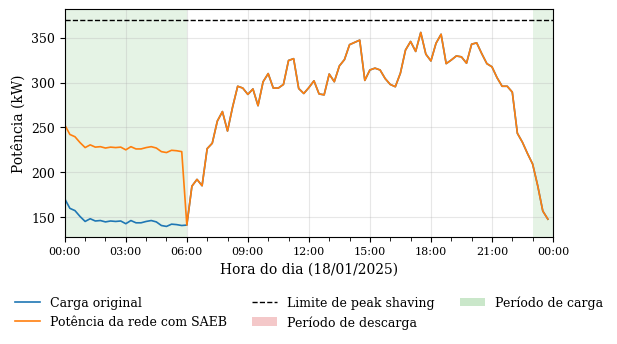

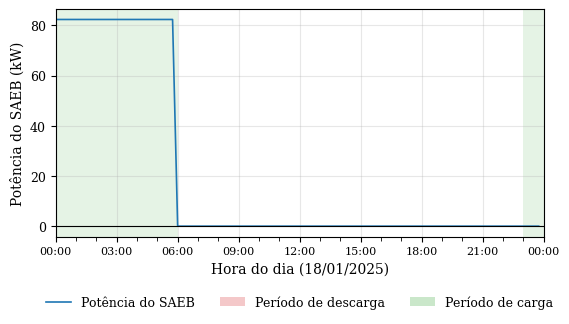

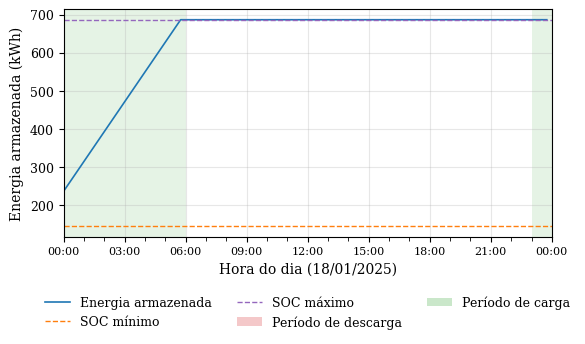

In [67]:
# Período de um dia: de 'inicio' até 'fim'
xlabel_dia = f"Hora do dia ({inicio:%d/%m/%Y})"

def eixo_dia(eixo):
    marcar_periodos(eixo, inicio, fim)
    formatar_eixo_x(eixo, inicio, fim, rotulo_h=3, menor_h=1,
                    fmt="%H:%M", xlabel=xlabel_dia)

# ------------------------------------------------------------------
# Carga original x potência da rede com SAEB
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=TAMANHO)
ax.plot(df_dia["data"], df_dia["potencia_kw"],
        label="Carga original", linewidth=1.2)
ax.plot(df_dia["data"], df_dia["Pot_Rede_kW"],
        label=f"Potência da rede com {NOME_SISTEMA}", linewidth=1.2)
ax.axhline(limite_demanda_kw, color="black", linestyle="--", linewidth=1.0,
           label="Limite de peak shaving")
eixo_dia(ax)
ax.set_ylabel("Potência (kW)")
legenda_abaixo(ax, ncol=3, y=-0.21, periodos=True)
salvar(fig, "fig_dia_carga_rede")

# ------------------------------------------------------------------
# Potência do SAEB (positiva: carga | negativa: descarga)
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=TAMANHO)
ax.plot(df_dia["data"], df_dia["Pot_Bateria_kW"],
        color="tab:blue", linewidth=1.2, label=f"Potência do {NOME_SISTEMA}")
ax.axhline(0, color="black", linewidth=0.8)
eixo_dia(ax)
ax.set_ylabel(f"Potência do {NOME_SISTEMA} (kW)")
legenda_abaixo(ax, ncol=3, y=-0.21, periodos=True)
salvar(fig, "fig_dia_potencia")

# ------------------------------------------------------------------
# Energia armazenada (kWh)
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=TAMANHO)
ax.plot(df_dia["data"], df_dia["SOC_kWh"],
        color="tab:blue", linewidth=1.2, label="Energia armazenada")
ax.axhline(capacidade * soc_min, linestyle="--", color="tab:orange",
           linewidth=1.0, label="SOC mínimo")
ax.axhline(capacidade * soc_max, linestyle="--", color="tab:purple",
           linewidth=1.0, label="SOC máximo")
eixo_dia(ax)
ax.set_ylabel("Energia armazenada (kWh)")
legenda_abaixo(ax, ncol=3, y=-0.21, periodos=True)
salvar(fig, "fig_dia_energia_armazenada")

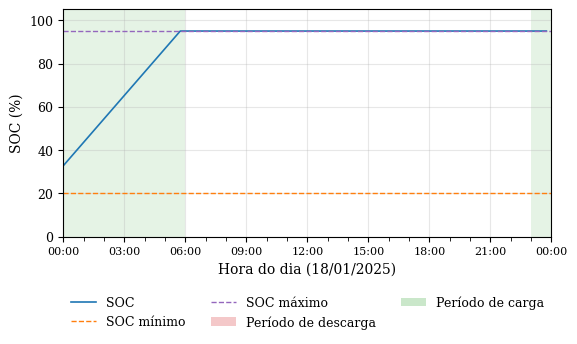

In [68]:
df_analise["SOC_percentual"] = (
    df_analise["SOC_kWh"] / capacidade
) * 100

df_dia = df_analise[
    (df_analise["data"] >= inicio) &
    (df_analise["data"] < fim)
].copy()

fig, ax = plt.subplots(figsize=TAMANHO)
ax.plot(df_dia["data"], df_dia["SOC_percentual"],
        color="tab:blue", linewidth=1.2, label="SOC")
ax.axhline(soc_min * 100, linestyle="--", color="tab:orange",
           linewidth=1.0, label="SOC mínimo")
ax.axhline(soc_max * 100, linestyle="--", color="tab:purple",
           linewidth=1.0, label="SOC máximo")
eixo_dia(ax)
ax.set_ylabel("SOC (%)")
ax.set_ylim(0, 105)
legenda_abaixo(ax, ncol=3, y=-0.21, periodos=True)
salvar(fig, "fig_dia_soc")

In [69]:
# Escolha a data inicial
data_inicial = pd.Timestamp("2025-09-04")

# O limite final não é incluído no filtro
# Assim, o intervalo cobre 5 dias a partir da data inicial
data_final = data_inicial + pd.Timedelta(days=5)

# Filtra o período
df_3dias = df_analise[
    (df_analise["data"] >= data_inicial) &
    (df_analise["data"] < data_final)
].copy()

print("Data inicial:", data_inicial)
print("Data final incluída:", data_final - pd.Timedelta(minutes=15))
print("Quantidade de registros:", len(df_3dias))

Data inicial: 2025-09-04 00:00:00
Data final incluída: 2025-09-08 23:45:00
Quantidade de registros: 480


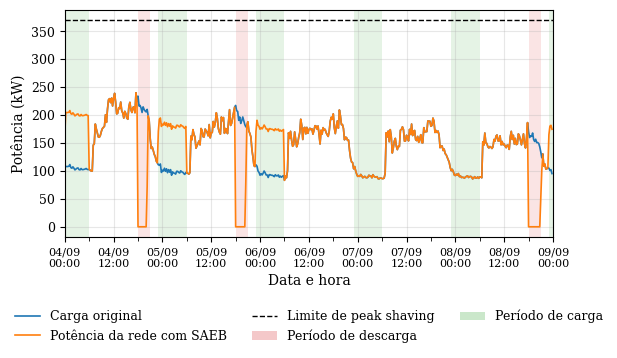

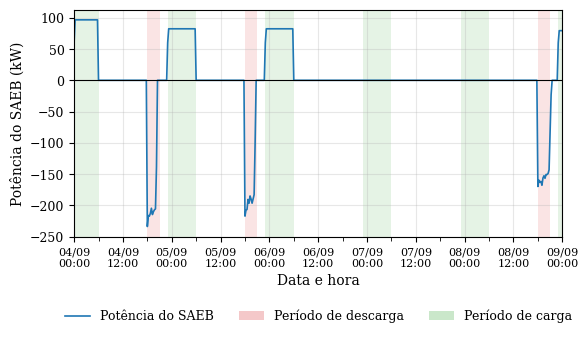

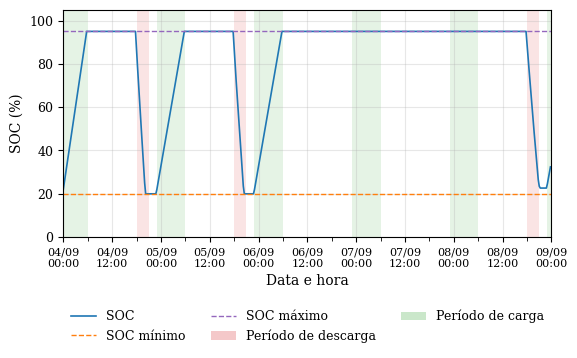

In [70]:
periodo_inicio = data_inicial.normalize()
periodo_fim = periodo_inicio + pd.Timedelta(days=5)

def eixo_3dias(eixo):
    marcar_periodos(eixo, periodo_inicio, periodo_fim)
    formatar_eixo_x(eixo, periodo_inicio, periodo_fim)

# ------------------------------------------------------------------
# Figura 1 - Carga original x potência da rede com SAEB
# ------------------------------------------------------------------
fig1, ax1 = plt.subplots(figsize=TAMANHO)
ax1.plot(df_3dias["data"], df_3dias["potencia_kw"],
         label="Carga original", linewidth=1.2)
ax1.plot(df_3dias["data"], df_3dias["Pot_Rede_kW"],
         label=f"Potência da rede com {NOME_SISTEMA}", linewidth=1.2)
ax1.axhline(limite_demanda_kw, color="black", linestyle="--", linewidth=1.0,
           label="Limite de peak shaving")
eixo_3dias(ax1)
ax1.set_ylabel("Potência (kW)")
legenda_abaixo(ax1, ncol=3, periodos=True)
salvar(fig1, "fig_bess_carga_rede")

# ------------------------------------------------------------------
# Figura 2 - Potência do SAEB
# ------------------------------------------------------------------
fig2, ax2 = plt.subplots(figsize=TAMANHO)
ax2.plot(df_3dias["data"], df_3dias["Pot_Bateria_kW"],
         color="tab:blue", linewidth=1.2, label=f"Potência do {NOME_SISTEMA}")
ax2.axhline(0, color="black", linewidth=0.8)
eixo_3dias(ax2)
ax2.set_ylabel(f"Potência do {NOME_SISTEMA} (kW)")
legenda_abaixo(ax2, ncol=3, periodos=True)
salvar(fig2, "fig_bess_potencia")

# ------------------------------------------------------------------
# Figura 3 - Estado de carga (SOC)
# ------------------------------------------------------------------
fig3, ax3 = plt.subplots(figsize=TAMANHO)
ax3.plot(df_3dias["data"], df_3dias["SOC_percentual"],
         color="tab:blue", linewidth=1.2, label="SOC")
ax3.axhline(soc_min * 100, linestyle="--", color="tab:orange",
            linewidth=1.0, label="SOC mínimo")
ax3.axhline(soc_max * 100, linestyle="--", color="tab:purple",
            linewidth=1.0, label="SOC máximo")
eixo_3dias(ax3)
ax3.set_ylabel("SOC (%)")
ax3.set_ylim(0, 105)
legenda_abaixo(ax3, ncol=3, periodos=True)
salvar(fig3, "fig_bess_soc")

In [71]:
# ==================================================
# Tarifas em R$/kWh ja com imposto obtido da conta 01-2026 (iguais às da solução 1)
# ==================================================

TE_ponta = 0.55610
TUSD_ponta = 0.906941

TE_fora_ponta = 0.34616
TUSD_fora_ponta = 0.164487

# ==================================================
# Classificação do posto tarifário
# Ponta: 18:00 até antes das 21:00, só em dias úteis (sem feriados)
# ==================================================

# CORREÇÃO: usa a coluna "periodo", que exclui sábados, domingos e feriados
# (é a classificação que bate com a fatura real)
condicao_ponta = df_analise["periodo"] == "Ponta"

df_analise["Posto_Tarifario"] = np.where(
    condicao_ponta,
    "Ponta",
    "Fora de ponta"
)

# ==================================================
# Tarifa total (TE + TUSD) por posto
# ==================================================

df_analise["Tarifa_Total_R_kWh"] = np.where(
    condicao_ponta,
    TE_ponta + TUSD_ponta,
    TE_fora_ponta + TUSD_fora_ponta
)

# ==================================================
# Conversão de potência para energia
# ==================================================

dt = 15 / 60  # intervalo de 15 minutos em horas

# Energia sem BESS
df_analise["Energia_sem_BESS_kWh"] = (
    df_analise["potencia_kw"] * dt
)

# Energia com BESS vista pela rede
# O clip impede contabilizar exportação como consumo negativo
df_analise["Energia_com_BESS_kWh"] = (
    df_analise["Pot_Rede_kW"].clip(lower=0) * dt
)

# ==================================================
# Custo de energia sem e com BESS
# ==================================================

df_analise["Custo_sem_BESS_R"] = (
    df_analise["Energia_sem_BESS_kWh"] * df_analise["Tarifa_Total_R_kWh"]
)
df_analise["Custo_com_BESS_R"] = (
    df_analise["Energia_com_BESS_kWh"] * df_analise["Tarifa_Total_R_kWh"]
)

In [72]:
# ==================================================
# Demanda Contratada (Grupo A4 - PRDOCMENTR101)
# ==================================================

# Sem BESS: demanda contratada real (contrato atual, sem peak shaving)
demanda_contratada_sem_bess_kw = 370.0

# Com BESS: demanda contratada (ajustar se o peak shaving permitir reduzir)
demanda_contratada_com_bess_kw = 360.0

# ==================================================
# TUSD de demanda por cenário
# ==================================================

# SEM BESS: contrato atual (mercado livre) - extraída da fatura real
TUSD_DEMANDA_SEM_BESS_COM_ICMS = 14.145855   # R$/kW

# COM BESS: mesma tarifa da solução 1
TUSD_DEMANDA_COM_BESS_COM_ICMS = 14.145855   # R$/kW

aliquota_icms = 0.19                  # mesma alíquota da solução 1

# Tarifa "líquida", sem o ICMS embutido, aplicada só sobre a parcela reservada e não usada
# (ICMS no Brasil é cobrado "por dentro", daí o desconto multiplicativo)
TUSD_DEMANDA_SEM_BESS_SEM_ICMS = TUSD_DEMANDA_SEM_BESS_COM_ICMS * (1 - aliquota_icms)
TUSD_DEMANDA_COM_BESS_SEM_ICMS = TUSD_DEMANDA_COM_BESS_COM_ICMS * (1 - aliquota_icms)

tolerancia_ultrapassagem = 0.05    # 5% (REN 1000/2021, art. 301)
multiplicador_ultrapassagem = 4    # tarifa de ultrapassagem = 2x a tarifa normal (confirme o valor exato na Copel)

df_analise["Mes_str"] = df_analise["data"].dt.to_period("M").astype(str)

demanda_medida_sem_bess = (
    df_analise.groupby("Mes_str")["potencia_kw"].max()
)

demanda_medida_com_bess = (
    df_analise.groupby("Mes_str")["Pot_Rede_kW"]
    .apply(lambda x: x.clip(lower=0).max())
)

def calcular_custo_demanda(demanda_medida, demanda_contratada,
                            tarifa_com_icms, tarifa_sem_icms,
                            tolerancia, multiplicador):

    limite_tolerado = demanda_contratada * (1 + tolerancia)

    # Parcela da demanda contratada que foi efetivamente utilizada
    # (tributada normalmente, com ICMS)
    parcela_utilizada = np.minimum(demanda_medida, demanda_contratada)
    custo_utilizada = parcela_utilizada * tarifa_com_icms

    # Parcela contratada mas não utilizada (reserva de potência ociosa)
    # -> não incide ICMS, por entendimento do STJ (Tema 176)
    parcela_nao_utilizada = np.maximum(demanda_contratada - demanda_medida, 0)
    custo_nao_utilizada = parcela_nao_utilizada * tarifa_sem_icms

    # Ultrapassagem acima da tolerância: cobrada com tarifa cheia (com ICMS) x multiplicador
    ultrapassagem = np.maximum(demanda_medida - limite_tolerado, 0)
    custo_ultrapassagem = ultrapassagem * tarifa_com_icms * multiplicador

    return custo_utilizada + custo_nao_utilizada + custo_ultrapassagem

# ==================================================
# Tarifa verde: demanda única no mês, a maior potência
# de 15 min em qualquer horário (ponta ou fora de ponta)
# ==================================================

custo_demanda_sem_bess = calcular_custo_demanda(
    demanda_medida_sem_bess, demanda_contratada_sem_bess_kw,
    TUSD_DEMANDA_SEM_BESS_COM_ICMS, TUSD_DEMANDA_SEM_BESS_SEM_ICMS,
    tolerancia_ultrapassagem, multiplicador_ultrapassagem
)

custo_demanda_com_bess = calcular_custo_demanda(
    demanda_medida_com_bess, demanda_contratada_com_bess_kw,
    TUSD_DEMANDA_COM_BESS_COM_ICMS, TUSD_DEMANDA_COM_BESS_SEM_ICMS,
    tolerancia_ultrapassagem, multiplicador_ultrapassagem
)

# ==================================================
# Conferência da composição da demanda faturada
# ==================================================

detalhe_demanda = pd.DataFrame({
    "Demanda medida sem BESS (kW)": demanda_medida_sem_bess,
    "Demanda medida com BESS (kW)": demanda_medida_com_bess,
    "Custo demanda sem BESS (R$)": custo_demanda_sem_bess.round(2),
    "Custo demanda com BESS (R$)": custo_demanda_com_bess.round(2),
})

print(f"TUSD demanda SEM BESS (com ICMS): R$ {TUSD_DEMANDA_SEM_BESS_COM_ICMS:.4f}/kW "
      f"| sem ICMS: R$ {TUSD_DEMANDA_SEM_BESS_SEM_ICMS:.4f}/kW")
print(f"TUSD demanda COM BESS (com ICMS): R$ {TUSD_DEMANDA_COM_BESS_COM_ICMS:.4f}/kW "
      f"| sem ICMS: R$ {TUSD_DEMANDA_COM_BESS_SEM_ICMS:.4f}/kW")
print(f"Alíquota de ICMS considerada: {aliquota_icms*100:.1f}%")
print()
print(detalhe_demanda)

TUSD demanda SEM BESS (com ICMS): R$ 14.1459/kW | sem ICMS: R$ 11.4581/kW
TUSD demanda COM BESS (com ICMS): R$ 14.1459/kW | sem ICMS: R$ 11.4581/kW
Alíquota de ICMS considerada: 19.0%

         Demanda medida sem BESS (kW)  Demanda medida com BESS (kW)  \
Mes_str                                                               
2025-01                       389.592                       381.024   
2025-02                       376.488                       370.000   
2025-03                       392.616                       370.000   
2025-04                       369.936                       369.936   
2025-05                       321.048                       310.464   
2025-06                       268.128                       268.128   
2025-07                       227.808                       227.808   
2025-08                       284.760                       284.760   
2025-09                       284.256                       267.624   
2025-10                       307.

In [73]:
# ==================================================
# Totais anuais
# ==================================================

fatura_energia_sem_bess = df_analise["Custo_sem_BESS_R"].sum()
fatura_energia_com_bess = df_analise["Custo_com_BESS_R"].sum()

fatura_demanda_sem_bess = custo_demanda_sem_bess.sum()
fatura_demanda_com_bess = custo_demanda_com_bess.sum()

fatura_sem_bess = fatura_energia_sem_bess + fatura_demanda_sem_bess
fatura_com_bess = fatura_energia_com_bess + fatura_demanda_com_bess

economia_anual = fatura_sem_bess - fatura_com_bess

if fatura_sem_bess > 0:
    economia_percentual = (economia_anual / fatura_sem_bess) * 100
else:
    economia_percentual = 0

print("=" * 55)
print("RESULTADO ANUAL DA SIMULAÇÃO")
print("=" * 55)

print(f"Fatura de energia sem BESS:  R$ {fatura_energia_sem_bess:,.2f}")
print(f"Fatura de demanda sem BESS:  R$ {fatura_demanda_sem_bess:,.2f}")
print(f"Fatura TOTAL sem BESS:       R$ {fatura_sem_bess:,.2f}")
print()
print(f"Fatura de energia com BESS:  R$ {fatura_energia_com_bess:,.2f}")
print(f"Fatura de demanda com BESS:  R$ {fatura_demanda_com_bess:,.2f}")
print(f"Fatura TOTAL com BESS:       R$ {fatura_com_bess:,.2f}")
print()
print(f"Economia anual:              R$ {economia_anual:,.2f}")
print(f"Economia percentual:         {economia_percentual:.2f}%")

RESULTADO ANUAL DA SIMULAÇÃO
Fatura de energia sem BESS:  R$ 983,783.00
Fatura de demanda sem BESS:  R$ 64,409.01
Fatura TOTAL sem BESS:       R$ 1,048,192.00

Fatura de energia com BESS:  R$ 868,354.07
Fatura de demanda com BESS:  R$ 59,845.32
Fatura TOTAL com BESS:       R$ 928,199.39

Economia anual:              R$ 119,992.61
Economia percentual:         11.45%


In [74]:
resumo_posto = (
    df_analise
    .groupby("Posto_Tarifario")
    .agg(
        Energia_sem_BESS_kWh=(
            "Energia_sem_BESS_kWh",
            "sum"
        ),
        Energia_com_BESS_kWh=(
            "Energia_com_BESS_kWh",
            "sum"
        ),
        Custo_sem_BESS_R=(
            "Custo_sem_BESS_R",
            "sum"
        ),
        Custo_com_BESS_R=(
            "Custo_com_BESS_R",
            "sum"
        )
    )
)

resumo_posto["Variacao_Energia_kWh"] = (
    resumo_posto["Energia_com_BESS_kWh"]
    - resumo_posto["Energia_sem_BESS_kWh"]
)

resumo_posto["Economia_R"] = (
    resumo_posto["Custo_sem_BESS_R"]
    - resumo_posto["Custo_com_BESS_R"]
)

display(resumo_posto.round(2))

,Energia_sem_BESS_kWh,Energia_com_BESS_kWh,Custo_sem_BESS_R,Custo_com_BESS_R,Variacao_Energia_kWh,Economia_R
Posto_Tarifario,,,,,,
Fora de ponta,1418228.60,1560819.55,724214.18,797027.82,142590.95,-72813.64
Ponta,177417.32,48752.05,259568.82,71326.25,-128665.27,188242.57


In [75]:
df_analise["Mes"] = (
    df_analise["data"]
    .dt
    .to_period("M")
    .astype(str)
)

fatura_mensal = (
    df_analise
    .groupby("Mes")
    .agg(
        Energia_sem_BESS_kWh=("Energia_sem_BESS_kWh", "sum"),
        Energia_com_BESS_kWh=("Energia_com_BESS_kWh", "sum"),
        Fatura_Energia_sem_BESS_R=("Custo_sem_BESS_R", "sum"),
        Fatura_Energia_com_BESS_R=("Custo_com_BESS_R", "sum"),
    )
    .reset_index()
)

fatura_mensal["Custo_Demanda_sem_BESS_R"] = fatura_mensal["Mes"].map(custo_demanda_sem_bess)
fatura_mensal["Custo_Demanda_com_BESS_R"] = fatura_mensal["Mes"].map(custo_demanda_com_bess)

fatura_mensal["Fatura_sem_BESS_R"] = (
    fatura_mensal["Fatura_Energia_sem_BESS_R"] + fatura_mensal["Custo_Demanda_sem_BESS_R"]
)
fatura_mensal["Fatura_com_BESS_R"] = (
    fatura_mensal["Fatura_Energia_com_BESS_R"] + fatura_mensal["Custo_Demanda_com_BESS_R"]
)

fatura_mensal["Economia_R"] = (
    fatura_mensal["Fatura_sem_BESS_R"] - fatura_mensal["Fatura_com_BESS_R"]
)

fatura_mensal["Economia_percentual"] = np.where(
    fatura_mensal["Fatura_sem_BESS_R"] > 0,
    (fatura_mensal["Economia_R"] / fatura_mensal["Fatura_sem_BESS_R"]) * 100,
    0
)

display(fatura_mensal.round(2))

,Mes,Energia_sem_BESS_kWh,Energia_com_BESS_kWh,Fatura_Energia_sem_BESS_R,Fatura_Energia_com_BESS_R,Custo_Demanda_sem_BESS_R,Custo_Demanda_com_BESS_R,Fatura_sem_BESS_R,Fatura_com_BESS_R,Economia_R,Economia_percentual
0,2025-01,180503.44,181576.67,112943.07,102737.75,5295.76,5263.62,118238.82,108001.37,10237.46,8.66
1,2025-02,156498.80,157611.84,97421.96,88179.60,5233.97,5092.51,102655.93,93272.11,9383.82,9.14
2,2025-03,171798.86,172915.90,104008.23,94766.37,5466.86,5092.51,109475.10,99858.88,9616.22,8.78
3,2025-04,130366.28,131479.32,79786.45,70542.54,5233.79,5092.51,85020.24,75635.05,9385.19,11.04
4,2025-05,127557.86,129220.59,78695.79,69241.96,5102.40,4959.37,83798.18,74201.33,9596.85,11.45
5,2025-06,102106.75,102731.25,62362.00,53207.09,4960.16,4845.58,67322.17,58052.68,9269.49,13.77
6,2025-07,102054.08,103296.68,63578.33,53211.98,4851.80,4737.21,68430.12,57949.19,10480.93,15.32
7,2025-08,100451.11,102093.15,61552.08,52562.67,5004.87,4890.28,66556.94,57452.96,9103.99,13.68
8,2025-09,106045.25,106773.59,66039.05,55728.11,5003.51,4844.23,71042.56,60572.34,10470.23,14.74
9,2025-10,117142.96,118422.18,73068.68,62509.46,5067.18,4894.35,78135.86,67403.81,10732.05,13.74


In [76]:
resumo_mensal_posto = (
    df_analise
    .groupby(["Mes", "Posto_Tarifario"])
    .agg(
        Energia_sem_BESS_kWh=(
            "Energia_sem_BESS_kWh",
            "sum"
        ),
        Energia_com_BESS_kWh=(
            "Energia_com_BESS_kWh",
            "sum"
        ),
        Custo_sem_BESS_R=(
            "Custo_sem_BESS_R",
            "sum"
        ),
        Custo_com_BESS_R=(
            "Custo_com_BESS_R",
            "sum"
        )
    )
    .reset_index()
)

resumo_mensal_posto["Variacao_Energia_kWh"] = (
    resumo_mensal_posto["Energia_com_BESS_kWh"]
    - resumo_mensal_posto["Energia_sem_BESS_kWh"]
)

resumo_mensal_posto["Economia_R"] = (
    resumo_mensal_posto["Custo_sem_BESS_R"]
    - resumo_mensal_posto["Custo_com_BESS_R"]
)

display(resumo_mensal_posto.round(2))

,Mes,Posto_Tarifario,Energia_sem_BESS_kWh,Energia_com_BESS_kWh,Custo_sem_BESS_R,Custo_com_BESS_R,Variacao_Energia_kWh,Economia_R
0,2025-01,Fora de ponta,158695.74,171059.84,81037.50,87351.19,12364.10,-6313.69
1,2025-01,Ponta,21807.70,10516.83,31905.56,15386.56,-11290.87,16519.00
2,2025-02,Fora de ponta,138117.42,149531.59,70529.25,76357.86,11414.17,-5828.61
3,2025-02,Ponta,18381.38,8080.26,26892.72,11821.75,-10301.13,15070.97
4,2025-03,Fora de ponta,154705.45,166125.24,78999.87,84831.35,11419.79,-5831.48
5,2025-03,Ponta,17093.41,6790.66,25008.36,9935.02,-10302.75,15073.35
6,2025-04,Fora de ponta,116490.40,127906.19,59485.47,65314.91,11415.79,-5829.44
7,2025-04,Ponta,13875.88,3573.13,20300.98,5227.63,-10302.75,15073.35
8,2025-05,Fora de ponta,113321.38,125801.99,57867.22,64240.41,12480.61,-6373.19
9,2025-05,Ponta,14236.49,3418.60,20828.57,5001.55,-10817.89,15827.01


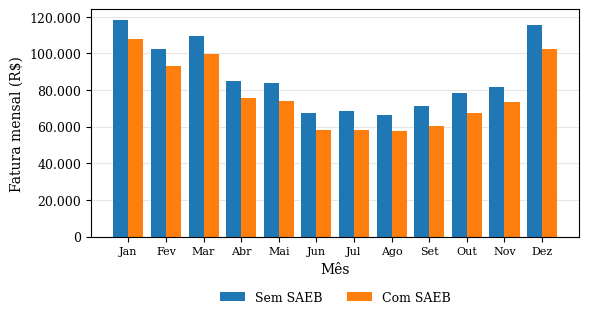

In [77]:
fig, ax = plt.subplots(figsize=TAMANHO)

barras_agrupadas(
    ax,
    rotulos_meses(fatura_mensal["Mes"]),
    {f"Sem {NOME_SISTEMA}": fatura_mensal["Fatura_sem_BESS_R"].values,
     f"Com {NOME_SISTEMA}": fatura_mensal["Fatura_com_BESS_R"].values}
)
ax.set_ylabel("Fatura mensal (R$)")
eixo_y_br(ax)
legenda_abaixo(ax, ncol=2, y=-0.19)
salvar(fig, "fig_fatura_mensal")

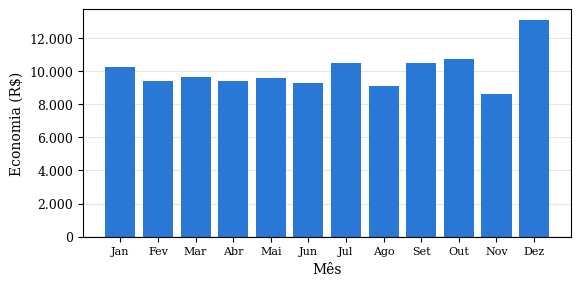

In [78]:
fig, ax = plt.subplots(figsize=TAMANHO)

ax.bar(rotulos_meses(fatura_mensal["Mes"]),
       fatura_mensal["Economia_R"].values,
       color="#2a78d6", zorder=2)
ax.axhline(0, color="black", linewidth=0.8)

estilo_barras(ax)
eixo_y_br(ax)
ax.set_xlabel("Mês")
ax.set_ylabel("Economia (R$)")
salvar(fig, "fig_economia_mensal")

In [79]:
# ==================================================
# Parâmetros econômicos - Cenário mediano
# ==================================================

investimento_inicial = 1_050_000.00  # R$ (3 módulos)

vida_util = 15                       # anos
tma = 0.05                           # 5% ao ano

# Crescimento anual das tarifas de energia
reajuste_tarifario = 0.08            # 8% ao ano

# Redução anual da economia devido à degradação do BESS
degradacao_bess = 0.02               # 2% ao ano

# Custo anual de operação e manutenção
# Neste exemplo: 1% do investimento inicial
percentual_om = 0.01
custo_om_inicial = investimento_inicial * percentual_om

# Crescimento anual do custo de manutenção
reajuste_om = 0.02                    # 2% ao ano

# ==================================================
# Economia obtida na simulação de 2025
# ==================================================

economia_ano_base = (
    fatura_sem_bess
    - fatura_com_bess
)

print(f"Economia do ano-base: R$ {economia_ano_base:,.2f}")

# ==================================================
# Construção do fluxo de caixa
# ==================================================

resultados_payback = []

# Ano zero: investimento inicial
fluxo_acumulado_simples = -investimento_inicial
fluxo_acumulado_descontado = -investimento_inicial

resultados_payback.append({
    "Ano": 0,
    "Economia_bruta_R": 0.0,
    "Custo_OM_R": 0.0,
    "Fluxo_liquido_R": -investimento_inicial,
    "Fator_desconto": 1.0,
    "Fluxo_descontado_R": -investimento_inicial,
    "Acumulado_simples_R": -investimento_inicial,
    "Acumulado_descontado_R": -investimento_inicial
})

for ano in range(1, vida_util + 1):

    # A economia cresce com a tarifa e diminui com a degradação
    economia_bruta = (
        economia_ano_base
        * (1 + reajuste_tarifario) ** (ano - 1)
        * (1 - degradacao_bess) ** (ano - 1)
    )

    # Custo de operação e manutenção
    custo_om = (
        custo_om_inicial
        * (1 + reajuste_om) ** (ano - 1)
    )

    # Benefício líquido anual
    fluxo_liquido = economia_bruta - custo_om

    # Valor presente do fluxo de caixa
    fator_desconto = 1 / (1 + tma) ** ano

    fluxo_descontado = (
        fluxo_liquido
        * fator_desconto
    )

    # Valores acumulados
    fluxo_acumulado_simples += fluxo_liquido
    fluxo_acumulado_descontado += fluxo_descontado

    resultados_payback.append({
        "Ano": ano,
        "Economia_bruta_R": economia_bruta,
        "Custo_OM_R": custo_om,
        "Fluxo_liquido_R": fluxo_liquido,
        "Fator_desconto": fator_desconto,
        "Fluxo_descontado_R": fluxo_descontado,
        "Acumulado_simples_R": fluxo_acumulado_simples,
        "Acumulado_descontado_R": fluxo_acumulado_descontado
    })

df_payback = pd.DataFrame(resultados_payback)

display(df_payback.round(2))

Economia do ano-base: R$ 119,992.61


,Ano,Economia_bruta_R,Custo_OM_R,Fluxo_liquido_R,Fator_desconto,Fluxo_descontado_R,Acumulado_simples_R,Acumulado_descontado_R
0,0,0.00,0.00,-1050000.00,1.00,-1050000.00,-1050000.00,-1050000.00
1,1,119992.61,10500.00,109492.61,0.95,104278.68,-940507.39,-945721.32
2,2,127000.18,10710.00,116290.18,0.91,105478.62,-824217.21,-840242.70
3,3,134416.99,10924.20,123492.79,0.86,106677.71,-700724.42,-733564.99
4,4,142266.94,11142.68,131124.26,0.82,107876.25,-569600.17,-625688.74
5,5,150575.33,11365.54,139209.79,0.78,109074.52,-430390.37,-516614.22
6,6,159368.93,11592.85,147776.08,0.75,110272.79,-282614.29,-406341.44
7,7,168676.08,11824.71,156851.37,0.71,111471.34,-125762.92,-294870.10
8,8,178526.76,12061.20,166465.56,0.68,112670.44,40702.64,-182199.65
9,9,188952.72,12302.42,176650.30,0.64,113870.36,217352.93,-68329.30


In [80]:
def calcular_payback(
    dataframe,
    coluna_acumulada,
    coluna_fluxo
):
    """
    Calcula o payback com interpolação dentro do ano.
    """

    recuperacao = dataframe[
        dataframe[coluna_acumulada] >= 0
    ]

    if recuperacao.empty:
        return None

    ano_recuperacao = int(
        recuperacao.iloc[0]["Ano"]
    )

    if ano_recuperacao == 0:
        return 0.0

    acumulado_anterior = dataframe.loc[
        dataframe["Ano"] == ano_recuperacao - 1,
        coluna_acumulada
    ].iloc[0]

    fluxo_ano_recuperacao = dataframe.loc[
        dataframe["Ano"] == ano_recuperacao,
        coluna_fluxo
    ].iloc[0]

    fracao_ano = (
        abs(acumulado_anterior)
        / fluxo_ano_recuperacao
    )

    return (
        ano_recuperacao - 1
        + fracao_ano
    )

payback_simples = calcular_payback(
    df_payback,
    "Acumulado_simples_R",
    "Fluxo_liquido_R"
)

payback_descontado = calcular_payback(
    df_payback,
    "Acumulado_descontado_R",
    "Fluxo_descontado_R"
)

print("=" * 55)
print("ANÁLISE ECONÔMICA DO BESS")
print("=" * 55)

print(
    f"Investimento inicial: "
    f"R$ {investimento_inicial:,.2f}"
)

print(
    f"Economia no ano-base: "
    f"R$ {economia_ano_base:,.2f}"
)

print(
    f"Custo de O&M no primeiro ano: "
    f"R$ {custo_om_inicial:,.2f}"
)

print(f"TMA: {tma * 100:.2f}% ao ano")

if payback_simples is None:
    print(
        f"Payback simples: não ocorre em "
        f"{vida_util} anos"
    )
else:
    print(
        f"Payback simples: "
        f"{payback_simples:.2f} anos"
    )

if payback_descontado is None:
    print(
        f"Payback descontado: não ocorre em "
        f"{vida_util} anos"
    )
else:
    print(
        f"Payback descontado: "
        f"{payback_descontado:.2f} anos"
    )

ANÁLISE ECONÔMICA DO BESS
Investimento inicial: R$ 1,050,000.00
Economia no ano-base: R$ 119,992.61
Custo de O&M no primeiro ano: R$ 10,500.00
TMA: 5.00% ao ano
Payback simples: 7.76 anos
Payback descontado: 9.59 anos


In [81]:
vpl = df_payback["Fluxo_descontado_R"].sum()

print(f"VPL do projeto: R$ {vpl:,.2f}")

if vpl > 0:
    print(
        "O projeto apresenta VPL positivo para a TMA adotada."
    )
elif vpl < 0:
    print(
        "O projeto apresenta VPL negativo para a TMA adotada."
    )
else:
    print(
        "O projeto apresenta VPL aproximadamente nulo."
    )

VPL do projeto: R$ 640,168.31
O projeto apresenta VPL positivo para a TMA adotada.


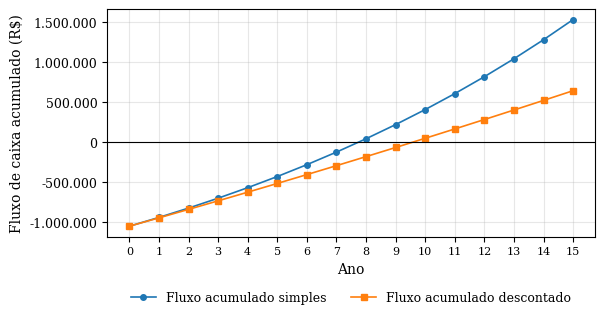

In [82]:
fig, ax = plt.subplots(figsize=TAMANHO)

ax.plot(df_payback["Ano"], df_payback["Acumulado_simples_R"],
        marker="o", markersize=4, linewidth=1.2,
        label="Fluxo acumulado simples")
ax.plot(df_payback["Ano"], df_payback["Acumulado_descontado_R"],
        marker="s", markersize=4, linewidth=1.2,
        label="Fluxo acumulado descontado")
ax.axhline(0, color="black", linewidth=0.8)

ax.set_xticks(df_payback["Ano"])
ax.set_xlabel("Ano")
ax.set_ylabel("Fluxo de caixa acumulado (R$)")
eixo_y_br(ax)
legenda_abaixo(ax, ncol=2, y=-0.19)
salvar(fig, "fig_payback")

In [83]:
# SOC ao final da janela de carregamento (06:00) em cada dia
soc_fim_carga = df_analise[
    (df_analise["data"].dt.hour == 5) &
    (df_analise["data"].dt.minute == 45)
][["data", "SOC_kWh"]].copy()

soc_fim_carga["SOC_percentual"] = (soc_fim_carga["SOC_kWh"] / capacidade) * 100

print(f"SOC médio às 06:00: {soc_fim_carga['SOC_percentual'].mean():.1f}%")
print(f"SOC mínimo às 06:00: {soc_fim_carga['SOC_percentual'].min():.1f}%")
print(f"Dias que não atingiram o SOC máximo ({soc_max*100:.0f}%): "
      f"{(soc_fim_carga['SOC_percentual'] < soc_max*100 - 1).sum()} de {len(soc_fim_carga)}")

print()
print("Pico máximo da rede no ano:", round(df_analise["Pot_Rede_kW"].max(), 2), "kW")
print(f"Limite tolerado ({demanda_contratada_com_bess_kw:.0f} kW + 5%): "
      f"{demanda_contratada_com_bess_kw * (1 + tolerancia_ultrapassagem):.2f} kW")

SOC médio às 06:00: 95.0%
SOC mínimo às 06:00: 95.0%
Dias que não atingiram o SOC máximo (95%): 0 de 365

Pico máximo da rede no ano: 381.02 kW
Limite tolerado (360 kW + 5%): 378.00 kW


In [84]:
# ==================================================
# Tabela mensal: fatura sem BESS x com BESS (R$)
# ==================================================

def fmt_reais(v):
    return "R$ " + f"{v:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")

tabela = fatura_mensal[
    ["Mes", "Fatura_sem_BESS_R", "Fatura_com_BESS_R", "Economia_R"]
].copy()

# Linha de total anual
total = {
    "Mes": "Total",
    "Fatura_sem_BESS_R": tabela["Fatura_sem_BESS_R"].sum(),
    "Fatura_com_BESS_R": tabela["Fatura_com_BESS_R"].sum(),
    "Economia_R": tabela["Economia_R"].sum(),
}
tabela = pd.concat([tabela, pd.DataFrame([total])], ignore_index=True)

# Economia percentual (calculada depois, para o total ficar correto)
tabela["Economia_%"] = tabela["Economia_R"] / tabela["Fatura_sem_BESS_R"] * 100

# Meses abreviados (Jan, Fev, ...) e Total
tabela["Mes"] = rotulos_meses(tabela["Mes"][:-1]) + ["Total"]

tabela_fmt = pd.DataFrame({
    "Mês": tabela["Mes"],
    "Sem SAEB (R$)": tabela["Fatura_sem_BESS_R"].map(fmt_reais),
    "Com SAEB (R$)": tabela["Fatura_com_BESS_R"].map(fmt_reais),
    "Economia (R$)": tabela["Economia_R"].map(fmt_reais),
    "Economia (%)": tabela["Economia_%"].map(lambda v: f"{v:.2f}".replace(".", ",") + "%"),
})

display(tabela_fmt)

,Mês,Sem SAEB (R$),Com SAEB (R$),Economia (R$),Economia (%)
0,Jan,"R$ 118.238,82","R$ 108.001,37","R$ 10.237,46","8,66%"
1,Fev,"R$ 102.655,93","R$ 93.272,11","R$ 9.383,82","9,14%"
2,Mar,"R$ 109.475,10","R$ 99.858,88","R$ 9.616,22","8,78%"
3,Abr,"R$ 85.020,24","R$ 75.635,05","R$ 9.385,19","11,04%"
4,Mai,"R$ 83.798,18","R$ 74.201,33","R$ 9.596,85","11,45%"
5,Jun,"R$ 67.322,17","R$ 58.052,68","R$ 9.269,49","13,77%"
6,Jul,"R$ 68.430,12","R$ 57.949,19","R$ 10.480,93","15,32%"
7,Ago,"R$ 66.556,94","R$ 57.452,96","R$ 9.103,99","13,68%"
8,Set,"R$ 71.042,56","R$ 60.572,34","R$ 10.470,23","14,74%"
9,Out,"R$ 78.135,86","R$ 67.403,81","R$ 10.732,05","13,74%"
